# Lab 03 (Example 1) — Model Representation, Explained Simply

This notebook covers the **same idea** as the original Lab 03, but with more explanation.

## What are we learning?

In supervised learning we have:
- **input** $x$ (for example: house size)
- **target** $y$ (for example: house price)

We want a model that can **predict** $y$ from $x$.

For linear regression with one variable, the model is:

$$
f_{w,b}(x) = wx + b
$$

| Symbol | Meaning |
|--------|---------|
| $x$ | input feature (size) |
| $w$ | weight / slope ("how much price changes per unit of size") |
| $b$ | bias / intercept ("base price when size is 0") |
| $f_{w,b}(x)$ | the **prediction** |

> **Short answer:** yes — `compute_model_output` is just this formula applied to every training example to make predictions.

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# Optional course style (works if the file is in this folder)
try:
    plt.style.use('./deeplearning.mplstyle')
except OSError:
    pass

## 1. Training data

We have only **2 houses** so the idea stays easy to see:

| House | Size $x$ (1000 sqft) | Price $y$ (1000s of dollars) |
|-------|----------------------|------------------------------|
| 1 | 1.0 | 300 |
| 2 | 2.0 | 500 |

So a 1000 sqft house costs $300k, and a 2000 sqft house costs $500k.

In [7]:
x_train = np.array([1.0, 2.0])  # input feature: size
y_train = np.array([300.0, 500.0])  # target: price

print(f"x_train = {x_train}")
print(f"y_train = {y_train}")
print(f"number of examples m = {len(x_train)}")

x_train = [1. 2.]
y_train = [300. 500.]
number of examples m = 2


## 2. Look at one example

In ML notation, the $i$-th training example is written $(x^{(i)}, y^{(i)})$.

In Python, indexing starts at **0**, so:
- $i = 0$ → first house
- $i = 1$ → second house

In [8]:
i = 0  # try changing this to 1

x_i = x_train[i]
y_i = y_train[i]

print(f"(x^({i}), y^({i})) = ({x_i}, {y_i})")

(x^(0), y^(0)) = (1.0, 300.0)


## 3. Plot the data

Red **x** markers = real house prices (the targets we already know).

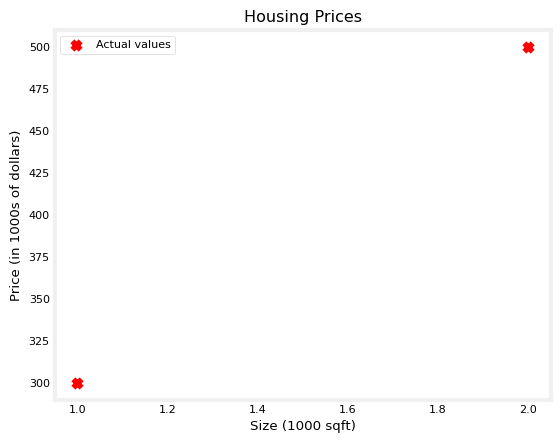

In [6]:
plt.scatter(x_train, y_train, marker='x', c='r', label='Actual values')
plt.title('Housing Prices')
plt.ylabel('Price (in 1000s of dollars)')
plt.xlabel('Size (1000 sqft)')
plt.legend()
plt.show()

## 4. Model parameters $w$ and $b$

A straight line needs two numbers:

- $w$ = slope
- $b$ = intercept

Think of it like:

> **predicted price = (price per 1000 sqft) × size + base price**

For this example we manually choose:
- $w = 200$
- $b = 100$

Later labs will teach how to **learn** good values of $w$ and $b$ automatically.

In [7]:
w = 200
b = 100

print(f"w (slope) = {w}")
print(f"b (intercept) = {b}")
print("prediction formula: f(x) = w * x + b")

w (slope) = 200
b (intercept) = 100
prediction formula: f(x) = w * x + b


## 5. What is `compute_model_output`?

### Yes — it is the regression formula used to make predictions.

For **one** house:

$$
f_{w,b}(x) = wx + b
$$

Example with $x = 1.0$, $w = 200$, $b = 100$:

$$
f = 200 \times 1.0 + 100 = 300
$$

For **many** houses, we repeat that formula for each $x$:

$$
f_{w,b}(x^{(i)}) = w x^{(i)} + b \quad \text{for } i = 0, 1, \dots, m-1
$$

That loop is exactly what `compute_model_output` does.

Important:
- Input: all $x$ values, plus chosen $w$ and $b$
- Output: predicted prices $\hat{y}$ (also written $f_{w,b}(x)$)
- It does **not** train the model. It only **applies** the formula.

In [8]:
def compute_model_output(x, w, b):
    """
    Apply the linear regression formula to every example.

        prediction = w * x + b

    Args:
      x (ndarray (m,)): sizes of m houses
      w, b (scalar): model parameters

    Returns:
      f_wb (ndarray (m,)): predicted prices for those houses
    """
    m = x.shape[0]          # how many houses?
    f_wb = np.zeros(m)      # empty array to store predictions

    for i in range(m):
        # THIS is the linear regression prediction formula
        f_wb[i] = w * x[i] + b

    return f_wb

### Walk through it by hand

With $w=200$, $b=100$:

| $i$ | $x^{(i)}$ | calculation | prediction $f$ |
|-----|-----------|-------------|----------------|
| 0 | 1.0 | $200 \times 1.0 + 100$ | 300 |
| 1 | 2.0 | $200 \times 2.0 + 100$ | 500 |

Here the predictions match the real prices. That means these $w$ and $b$ fit this tiny dataset well.

In [9]:
predictions = compute_model_output(x_train, w, b)

print(f"inputs x      = {x_train}")
print(f"actual y      = {y_train}")
print(f"predictions f = {predictions}")

# Same math, one house at a time (no function needed)
print()
print("Manual check:")
print(f"  house 0: {w}*{x_train[0]} + {b} = {w * x_train[0] + b}")
print(f"  house 1: {w}*{x_train[1]} + {b} = {w * x_train[1] + b}")

inputs x      = [1. 2.]
actual y      = [300. 500.]
predictions f = [300. 500.]

Manual check:
  house 0: 200*1.0 + 100 = 300.0
  house 1: 200*2.0 + 100 = 500.0


## 6. Plot predictions vs actual values

- Blue line = model predictions $f_{w,b}(x)$
- Red x = real targets $y$

If the blue line goes through the red points, the model fits well.

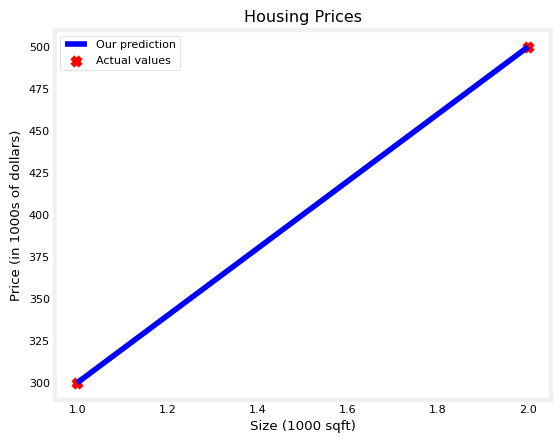

In [10]:
plt.plot(x_train, predictions, c='b', label='Our prediction')
plt.scatter(x_train, y_train, marker='x', c='r', label='Actual values')
plt.title('Housing Prices')
plt.ylabel('Price (in 1000s of dollars)')
plt.xlabel('Size (1000 sqft)')
plt.legend()
plt.show()

## 7. Predict a new house (the useful part)

Training data taught us the pattern. Now predict a house we have **not** seen.

Example: size = 1.2 → 1200 sqft

$$
f = 200 \times 1.2 + 100 = 340
$$

So the model predicts **$340,000**.

In [11]:
x_new = 1.2
price_pred = w * x_new + b   # same formula again!

print(f"Size = {x_new} thousand sqft")
print(f"Predicted price = ${price_pred:.0f} thousand dollars")

Size = 1.2 thousand sqft
Predicted price = $340 thousand dollars


## 8. Try different $w$ and $b$ (optional experiment)

Change $w$ or $b$ below and re-run. Watch how the blue line moves.

This builds intuition:
- bigger $w$ → steeper line
- bigger $b$ → line shifts up

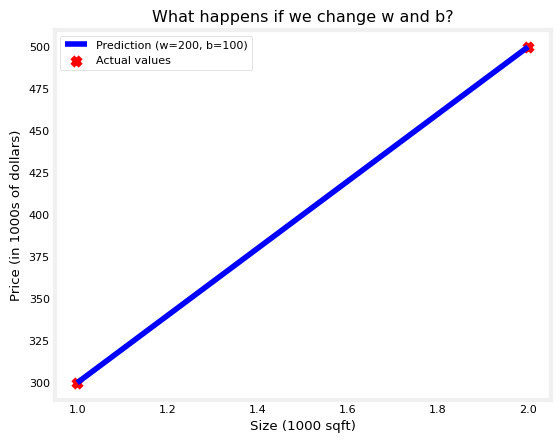

predictions with w=200, b=100: [300. 500.]
actual targets:                      [300. 500.]


In [16]:
w_try = 200   # try 100, 200, 300...
b_try = 100   # try 0, 100, 200...

pred_try = compute_model_output(x_train, w_try, b_try)

plt.plot(x_train, pred_try, c='b', label=f'Prediction (w={w_try}, b={b_try})')
plt.scatter(x_train, y_train, marker='x', c='r', label='Actual values')
plt.title('What happens if we change w and b?')
plt.ylabel('Price (in 1000s of dollars)')
plt.xlabel('Size (1000 sqft)')
plt.legend()
plt.show()

print(f"predictions with w={w_try}, b={b_try}: {pred_try}")
print(f"actual targets:                      {y_train}")

## Quick recap

1. Linear regression model: $f_{w,b}(x) = wx + b$
2. `compute_model_output(x, w, b)` applies that formula to each example → **predictions**
3. It is **not** training. Training (finding good $w,b$) comes in later labs.
4. Once you have $w$ and $b$, you can predict prices for new house sizes.

### One-line mental model

> `compute_model_output` = "plug every $x$ into $wx + b$ and return the predicted prices."